# 06 · Sensitivity analysis: does left-censored missingness change the COG results?

Notebook 01 (missingness figure) showed that missing values are **left-censored and platform-specific**: each batch stops detecting proteins below its own limit, and Schmidt 2016 reports trace values where the other platforms report nothing. The primary analysis (notebook 03) imputes nothing: an undetected protein contributes zero mass.

This notebook asks whether that choice matters. It re-runs **exactly the notebook-03 model** under alternative treatments of censored values and compares the results.

| scenario | what is done to the data |
|---|---|
| **A · zero** | as notebook 03: undetected = 0 mass (reference) |
| **B · common floor** | every value below the *highest* batch detection limit is set to 0, so every platform is censored identically, as if all had the weakest instrument. Schmidt's trace values are removed. |
| **C · impute ½ LLOD** | each undetected protein gets min(its abundance in the other datasets, ½ × its batch's detection limit) |
| **D · impute LLOD (upper bound)** | as C, with the full batch detection limit: the most mass undetected proteins could plausibly carry |

**Instrument-specific penalty.** In C and D the imputed value is capped by the detection limit **of the batch where the protein was missed**, so a deep platform (low limit) receives smaller fill values than a shallow one. Proteins never quantified in any dataset stay 0; they are most likely not expressed.

**Isolation.** Reads only the files written by notebooks 01–02 and writes only files prefixed `06_`. No other notebook reads them. The results are a robustness check; they do not replace notebook 03.

In [1]:
import sys
from pathlib import Path

# repository root = first parent folder that contains config.yml (no machine-specific paths)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yml").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from proteome_alloc import config, ingest, annotation, scope, allocation, asca, predict, plots
from proteome_alloc.ingest import GROWTH

cfg = config.load_config()
pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 60)
print("Repository root :", cfg.root)
print("Config file     :", cfg.config_file.name, "| master seed:", cfg["seed"])

Repository root : C:\Users\arlin\OneDrive\Documentos\proteome_allocation\proteome_allocation
Config file     : config.yml | master seed: 20261011


In [2]:
X, obs, var = scope.load_scoped(cfg)
annotation_table = annotation.load_annotation(cfg)
labels = annotation.category_labels(cfg)
batch_key = cfg["allocation"]["batch_key"]
in_scope = obs.index[obs["In_Scope"]]
print(f"{len(in_scope)} in-scope runs, {obs.loc[in_scope, batch_key].nunique()} batches, batch key = {batch_key}")

36 in-scope runs, 6 batches, batch key = MS_Batch


## 1 · Detection limit of every batch, estimated from the data

For each batch, proteins are binned by their abundance **in the other datasets** (leave-dataset-out, so a protein's own detection does not set its abundance). The detection limit (LLOD50) is the lowest abundance bin from which the batch quantifies at least 50 % of proteins in every higher bin. This is robust to the noisy low-abundance tail visible for Mori in notebook 01.

In [3]:
STEP, MIN_PROTEINS, DETECTION_TARGET = 0.25, 10, 0.5      # log10 bin width, proteins per bin, detection share
log_q = np.log10(X.where(X > 0))
reference_elsewhere = {d: log_q.loc[obs.index[obs["Dataset_Source"] != d]].mean()
                       for d in obs["Dataset_Source"].unique()}  # mean log10 abundance in the OTHER datasets

llod, rows = {}, []
for b, members in obs.groupby(batch_key).groups.items():
    dataset = obs.loc[members, "Dataset_Source"].iloc[0]
    reference = reference_elsewhere[dataset]
    detected = (X.loc[members] > 0).mean()
    ok = reference.notna()
    bins = np.floor(reference[ok] / STEP) * STEP
    curve = detected[ok].groupby(bins).agg(["mean", "size"])
    curve = curve[curve["size"] >= MIN_PROTEINS].sort_index()
    stays_above = (curve["mean"] >= DETECTION_TARGET)[::-1].cumprod()[::-1].astype(bool)
    llod_log = float(curve.index[stays_above].min() + STEP / 2) if stays_above.any() else np.nan
    llod[b] = 10 ** llod_log
    quantified = X.loc[members].where(X.loc[members] > 0)
    rows.append({batch_key: b, "Dataset_Source": dataset, "runs": len(members),
                 "LLOD50_log10": round(llod_log, 2),
                 "lowest_reported_log10": round(float(np.log10(quantified.min().min())), 2),
                 "median_quantified_per_run": int((X.loc[members] > 0).sum(axis=1).median()),
                 "quantified_values_below_LLOD50_%": round(100 * float((quantified < llod[b]).sum().sum())
                                                          / float(quantified.notna().sum().sum()), 1)})
llod_table = pd.DataFrame(rows).set_index(batch_key).sort_values("LLOD50_log10")
common_floor = max(llod.values())
display(llod_table)
print(f"Common floor for scenario B = highest batch LLOD50 = 10^{np.log10(common_floor):.2f}")

,Dataset_Source,runs,LLOD50_log10,lowest_reported_log10,median_quantified_per_run,quantified_values_below_LLOD50_%
MS_Batch,,,,,,
mori_2021,mori_2021,19,-5.38,-7.77,2024,1.4
Group3,wu_2023,13,-4.62,-8.61,1833,9.6
schmidt_2016,schmidt_2016,2,-4.62,-9.10,1986,40.5
Group1,wu_2023,6,-4.38,-7.41,1674,19.5
Group2,wu_2023,2,-4.38,-7.01,1629,17.8
Zhu_2025,zhu_2025,12,-4.12,-6.00,1434,25.5


Common floor for scenario B = highest batch LLOD50 = 10^-4.12


`lowest_reported_log10` far below `LLOD50_log10` means the batch reports trace values beneath the abundance at which it reliably detects proteins. This is the Schmidt pattern. Scenario B removes those values.

## 2 · Build the four scenarios

In [4]:
def common_floor_censoring(M: pd.DataFrame) -> pd.DataFrame:
    """Scenario B: every quantified value below the common floor becomes 'not detected' (0)."""
    return M.mask((M > 0) & (M < common_floor), 0.0)


def impute_batch_llod(M: pd.DataFrame, factor: float) -> pd.DataFrame:
    """Scenarios C/D: undetected -> min(abundance in other datasets, factor x LLOD of this batch).
    Proteins never quantified in another dataset stay NaN, i.e. 0 mass."""
    out = M.copy()
    for b, members in obs.loc[M.index].groupby(batch_key).groups.items():
        dataset = obs.loc[members[0], "Dataset_Source"]
        fill = np.minimum(10 ** reference_elsewhere[dataset], factor * llod[b])     # per protein
        block = out.loc[members]
        out.loc[members] = block.where(block > 0, fill, axis=1)
    return out


Xs = X.loc[in_scope]
scenarios = {
    "A · zero (notebook 03)": Xs,
    "B · common floor": common_floor_censoring(Xs),
    "C · impute ½ LLOD": impute_batch_llod(Xs, 0.5),
    "D · impute LLOD (upper bound)": impute_batch_llod(Xs, 1.0),
}

# how much mass each scenario adds or removes, per batch (before renormalisation)
change = pd.DataFrame({name: (M.fillna(0).sum(axis=1) - Xs.fillna(0).sum(axis=1)) * 100
                       for name, M in scenarios.items()})
display(change.groupby(obs.loc[in_scope, batch_key]).mean().round(3)
        .rename(columns=lambda c: c + " (Δ % mass)"))

,A · zero (notebook 03) (Δ % mass),B · common floor (Δ % mass),C · impute ½ LLOD (Δ % mass),D · impute LLOD (upper bound) (Δ % mass)
MS_Batch,,,,
Group1,0.0,-2.485,1.342,2.070
Group2,0.0,-2.379,1.404,2.126
Group3,0.0,-2.789,0.693,1.175
Zhu_2025,0.0,-2.235,1.760,2.459
mori_2021,0.0,-3.029,0.066,0.124
schmidt_2016,0.0,-2.329,0.587,1.027


Read this table before the results. If the imputed mass (C, D) is a few percent at most, the zero-mass choice of notebook 03 can only shift category shares slightly. The column for B shows how much quantified mass a common detection floor removes.

## 3 · Re-run the notebook-03 model under each scenario

In [5]:
results = {}
for name, M in scenarios.items():
    F, _ = allocation.cog_fractions(M, annotation_table, cfg)
    Fc, info = allocation.aggregate_conditions(F, obs.loc[in_scope], cfg)
    table, _ = allocation.fit_growth_laws(Fc, info, cfg)
    results[name] = table
    print(f"{name:32s} significant categories: {int(table['significant'].sum())}")

reference_name = "A · zero (notebook 03)"
tested = results[reference_name].index[results[reference_name]["tested"]]
slopes = pd.DataFrame({name: t.loc[tested, "slope_per_h-1"] * 100 for name, t in results.items()})
significant = pd.DataFrame({name: t.loc[tested, "significant"] for name, t in results.items()})

summary = []
for name in results:
    same_sign = np.sign(slopes[name]) == np.sign(slopes[reference_name])
    summary.append({"scenario": name,
                    "significant categories": int(significant[name].sum()),
                    "same sign as A (%)": round(100 * same_sign.mean(), 1),
                    "same significance call as A (%)": round(100 * (significant[name] == significant[reference_name]).mean(), 1),
                    "Spearman r of slopes vs A": round(slopes[name].corr(slopes[reference_name], method="spearman"), 3),
                    "largest |slope change| (points per h-1)": round((slopes[name] - slopes[reference_name]).abs().max(), 3)})
summary = pd.DataFrame(summary).set_index("scenario")
display(summary)

A · zero (notebook 03)           significant categories: 14
B · common floor                 significant categories: 14
C · impute ½ LLOD                significant categories: 14
D · impute LLOD (upper bound)    significant categories: 14


,significant categories,same sign as A (%),same significance call as A (%),Spearman r of slopes vs A,largest |slope change| (points per h-1)
scenario,,,,,
A · zero (notebook 03),14,100.0,100.0,1.000,0.000
B · common floor,14,100.0,100.0,0.999,0.380
C · impute ½ LLOD,14,100.0,100.0,0.997,0.213
D · impute LLOD (upper bound),14,100.0,100.0,0.997,0.331


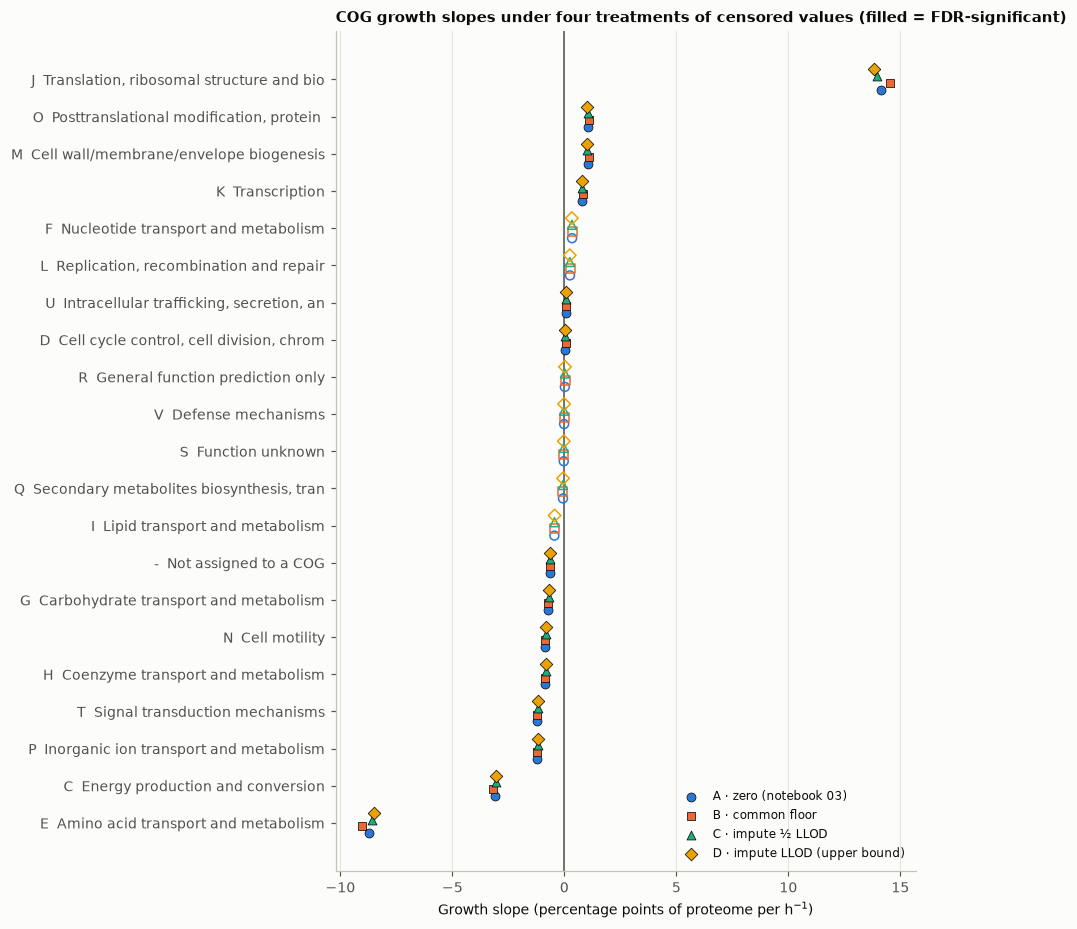

In [6]:
order = slopes[reference_name].sort_values().index
styles = {"A · zero (notebook 03)": ("#2a78d6", "o"), "B · common floor": ("#eb6834", "s"),
          "C · impute ½ LLOD": ("#1baf7a", "^"), "D · impute LLOD (upper bound)": ("#eda100", "D")}
fig, ax = plt.subplots(figsize=(8.5, 0.32 * len(order) + 1.8))
offsets = np.linspace(-0.27, 0.27, len(slopes.columns))
for offset, name in zip(offsets, slopes.columns):
    colour, marker = styles[name]
    filled = significant.loc[order, name].to_numpy()
    y = np.arange(len(order)) + offset
    ax.scatter(slopes.loc[order, name][filled], y[filled], color=colour, marker=marker, s=34,
               edgecolor="#0b0b0b", linewidth=0.5, label=name, zorder=3)
    ax.scatter(slopes.loc[order, name][~filled], y[~filled], facecolors="none", edgecolors=colour,
               marker=marker, s=34, linewidth=1, zorder=3)
ax.axvline(0, color="#52514e", linewidth=1)
ax.set_yticks(range(len(order)), [f"{c}  {labels.get(c, '')[:40]}" for c in order])
ax.set_xlabel("Growth slope (percentage points of proteome per h$^{-1}$)")
ax.set_title("COG growth slopes under four treatments of censored values (filled = FDR-significant)")
ax.grid(axis="y", visible=False)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(cfg.figures / "06_sensitivity_censoring_slopes.png", dpi=200, bbox_inches="tight")
plt.show()

**How to read it.** Each category has four markers, one per scenario. If they sit together and keep their filling (significant or not), the result does not depend on how censored values are treated. Report any category whose sign or significance changes, and name the scenario that changes it.

## 4 · Protein filters before ASCA: dataset-aware AND vs alternatives

Notebook 04 keeps a protein only if it is quantified in at least the threshold share of in-scope runs **in every dataset** (computed per dataset, combined with AND). The table shows how many proteins other rules would keep, and how much of the resulting matrix would then have to be imputed. It only counts; nothing is changed.

In [7]:
detected = (Xs.fillna(0) > 0)
by_dataset = detected.groupby(obs.loc[in_scope, "Dataset_Source"]).mean()
by_batch = detected.groupby(obs.loc[in_scope, batch_key]).mean()
pooled = detected.mean()

def describe(rule: str, keep: pd.Series) -> dict:
    block = Xs.loc[:, keep]
    return {"rule": rule, "proteins kept": int(keep.sum()),
            "cells needing imputation (%)": round(100 * float((~(block > 0)).to_numpy().mean()), 1) if keep.any() else np.nan,
            "proteome mass covered, min over runs (%)": round(100 * float(block.fillna(0).sum(axis=1).min()), 1) if keep.any() else np.nan}

rules = [
    ("AND over datasets, 100 % (notebook 04 default)", (by_dataset >= 1.0).all()),
    ("AND over datasets, 80 %", (by_dataset >= 0.8).all()),
    ("AND over batches, 100 %", (by_batch >= 1.0).all()),
    ("Global: pooled over all runs, 80 %", pooled >= 0.8),
    ("OR over datasets, 80 % (original notebook rule)", (by_dataset >= 0.8).any()),
]
for d in by_dataset.index:
    rules.append((f"AND over datasets, 100 %, without {d}", (by_dataset.drop(index=d) >= 1.0).all()))
filters = pd.DataFrame([describe(rule, keep) for rule, keep in rules]).set_index("rule")
display(filters)

,proteins kept,cells needing imputation (%),"proteome mass covered, min over runs (%)"
rule,,,
"AND over datasets, 100 % (notebook 04 default)",1188,0.0,80.3
"AND over datasets, 80 %",1416,0.9,91.0
"AND over batches, 100 %",1188,0.0,80.3
"Global: pooled over all runs, 80 %",1539,2.0,94.4
"OR over datasets, 80 % (original notebook rule)",2247,20.4,98.7
"AND over datasets, 100 %, without mori_2021",1222,0.1,81.4
"AND over datasets, 100 %, without schmidt_2016",1203,0.1,82.4
"AND over datasets, 100 %, without wu_2023",1367,2.1,81.3
"AND over datasets, 100 %, without zhu_2025",1238,0.4,86.3


* **AND (default):** every protein is measured in every study, so nothing is imputed. The shallowest dataset sets the size of the protein set.
* **Global pooled filter:** dominated by the dataset with most runs (Wu has 21). A protein absent from a small study can pass, so whole study blocks would need imputation. This is not dataset-aware.
* **OR:** protects proteins that only the deep platforms measure, but requires imputing them in every study that never saw them. That is the structural missingness the original notebook filled with half-minimum values.
* **"without X" rows:** show which study limits the protein set. If dropping one study gains many proteins, a version of the ASCA without it is a reasonable additional analysis.

In [8]:
outputs = [cfg.tables / "06_batch_detection_limits.tsv", cfg.tables / "06_sensitivity_summary.tsv",
           cfg.tables / "06_sensitivity_slopes.tsv", cfg.tables / "06_protein_filter_alternatives.tsv"]
llod_table.to_csv(outputs[0], sep="\t"); summary.to_csv(outputs[1], sep="\t")
slopes.join(significant.add_suffix(" significant")).to_csv(outputs[2], sep="\t"); filters.to_csv(outputs[3], sep="\t")
config.log_run(cfg, "06_sensitivity_censoring",
               params={"detection_target": DETECTION_TARGET, "bin_step": STEP, "min_proteins_per_bin": MIN_PROTEINS,
                       "common_floor_log10": float(np.log10(common_floor)), "scenarios": list(scenarios)},
               outputs=outputs, notes={"LLOD50_log10": llod_table["LLOD50_log10"].to_dict()})
print("Written:", *[p.relative_to(cfg.root) for p in outputs], sep="\n  ")

Written:
  results\tables\06_batch_detection_limits.tsv
  results\tables\06_sensitivity_summary.tsv
  results\tables\06_sensitivity_slopes.tsv
  results\tables\06_protein_filter_alternatives.tsv
